In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import make_pipeline

In [2]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


In [3]:
data=pd.read_csv("C:\\Users\\acer\\Downloads\\telescope_data.zip")
data

,Unnamed: 0,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g
...,...,...,...,...,...,...,...,...,...,...,...,...
19015,19015,21.3846,10.9170,2.6161,0.5857,0.3934,15.2618,11.5245,2.8766,2.4229,106.8258,h
19016,19016,28.9452,6.7020,2.2672,0.5351,0.2784,37.0816,13.1853,-2.9632,86.7975,247.4560,h
19017,19017,75.4455,47.5305,3.4483,0.1417,0.0549,-9.3561,41.0562,-9.4662,30.2987,256.5166,h
19018,19018,120.5135,76.9018,3.9939,0.0944,0.0683,5.8043,-93.5224,-63.8389,84.6874,408.3166,h


In [4]:
data.columns=[cols.lower() for cols in data.columns]
print(data.columns)

Index(['unnamed: 0', 'flength', 'fwidth', 'fsize', 'fconc', 'fconc1', 'fasym',
       'fm3long', 'fm3trans', 'falpha', 'fdist', 'class'],
      dtype='str')


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   unnamed: 0  19020 non-null  int64  
 1   flength     19020 non-null  float64
 2   fwidth      19020 non-null  float64
 3   fsize       19020 non-null  float64
 4   fconc       19020 non-null  float64
 5   fconc1      19020 non-null  float64
 6   fasym       19020 non-null  float64
 7   fm3long     19020 non-null  float64
 8   fm3trans    19020 non-null  float64
 9   falpha      19020 non-null  float64
 10  fdist       19020 non-null  float64
 11  class       19020 non-null  str    
dtypes: float64(10), int64(1), str(1)
memory usage: 1.7 MB


In [6]:
data.isna().sum()

unnamed: 0    0
flength       0
fwidth        0
fsize         0
fconc         0
fconc1        0
fasym         0
fm3long       0
fm3trans      0
falpha        0
fdist         0
class         0
dtype: int64

In [7]:
data.describe()

,unnamed: 0,flength,fwidth,fsize,fconc,fconc1,fasym,fm3long,fm3trans,falpha,fdist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,9509.500000,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,5490.745396,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,0.000000,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,4754.750000,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,9509.500000,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,14264.250000,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,19019.000000,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


In [8]:
data.head()

,unnamed: 0,flength,fwidth,fsize,fconc,fconc1,fasym,fm3long,fm3trans,falpha,fdist,class
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


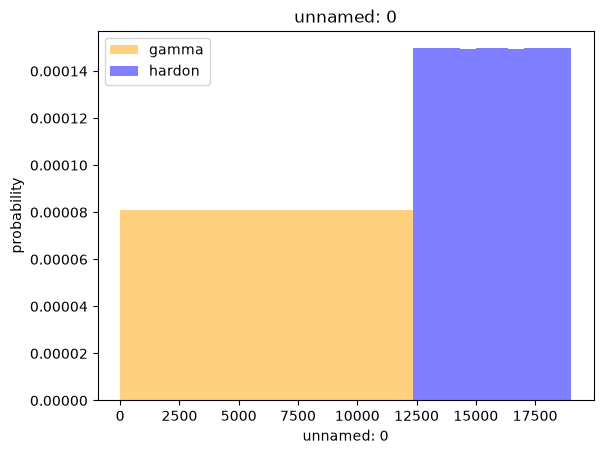

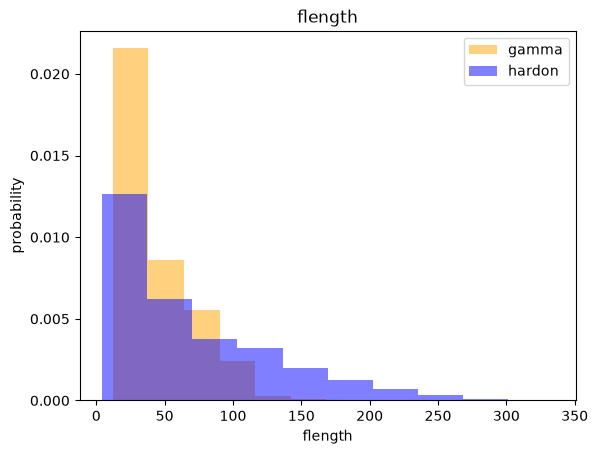

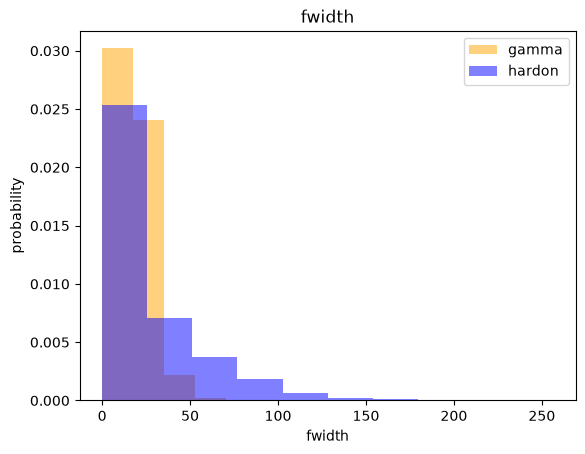

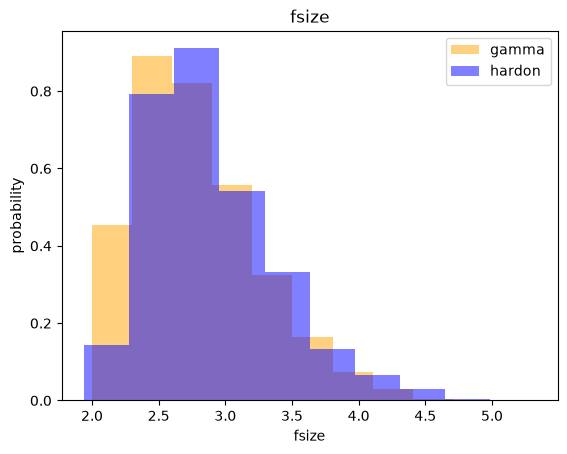

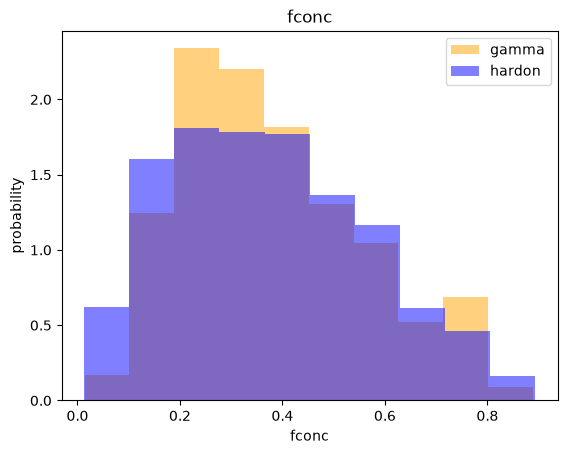

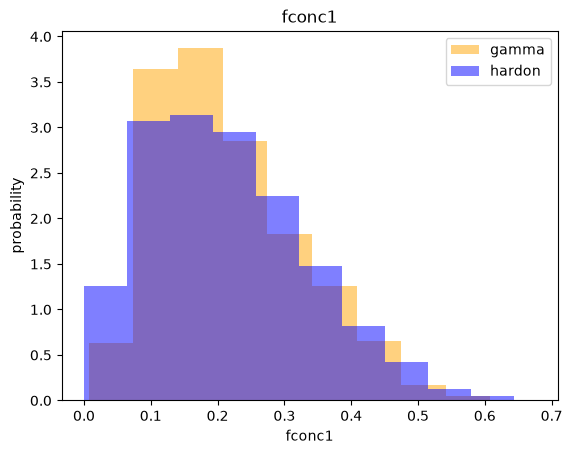

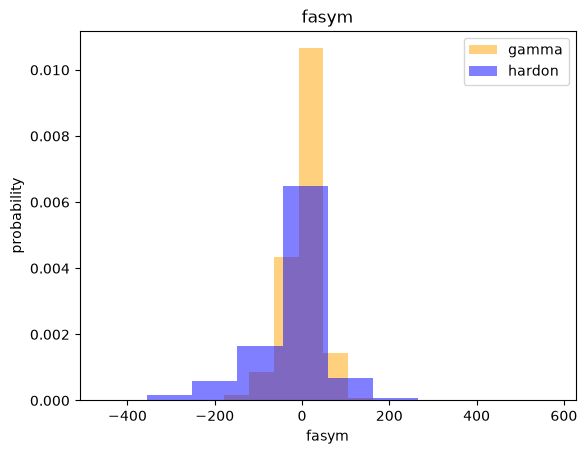

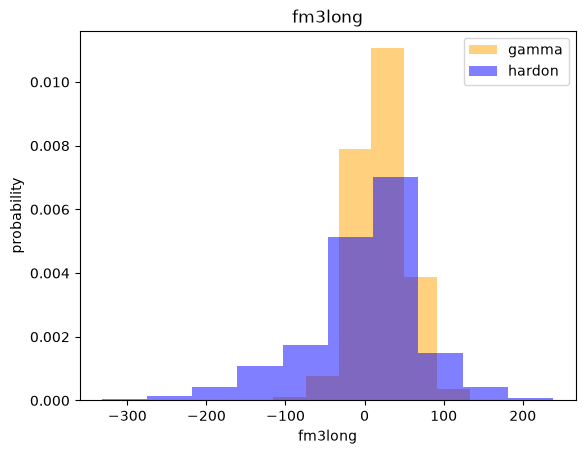

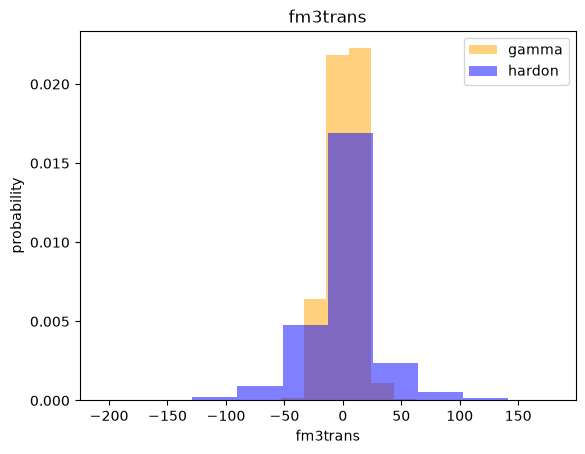

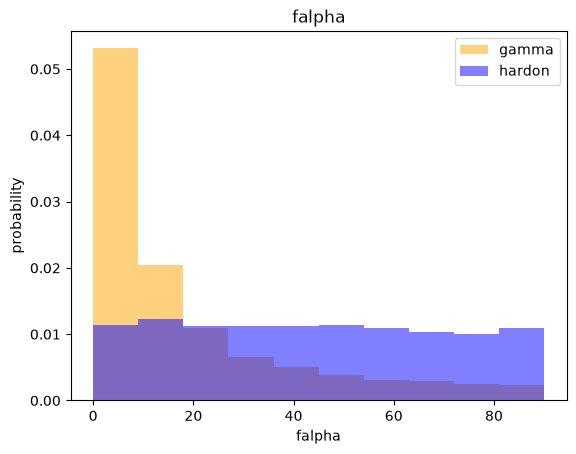

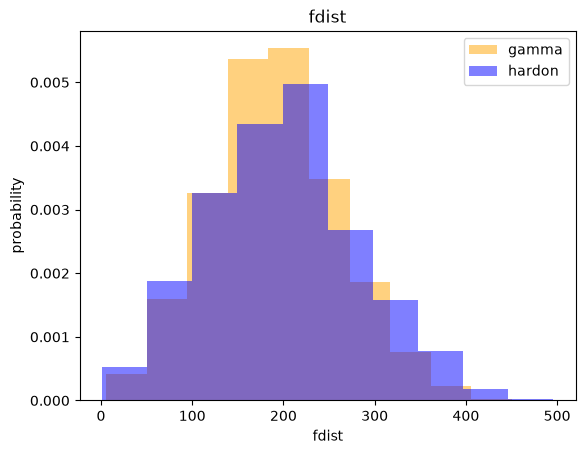

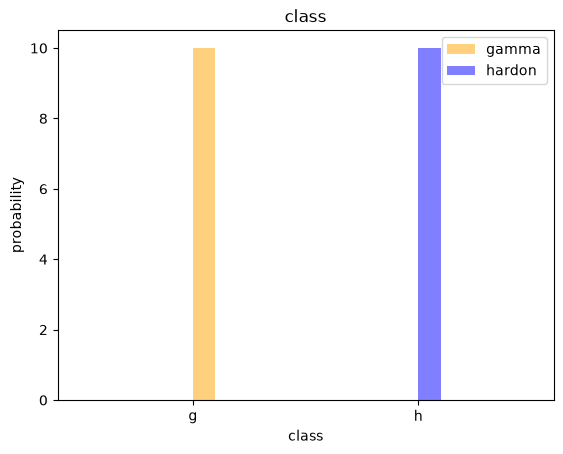

In [9]:
for label in (data.columns):
    plt.hist(data[data["class"]=="g"][label],color="orange",label="gamma",alpha=0.5,density=True)
    plt.hist(data[data["class"]=="h"][label],color="blue",label="hardon",alpha=0.5,density=True)
    plt.title(label)
    plt.xlabel(label)
    plt.ylabel("probability")
    plt.legend()
    plt.show();

In [10]:
print(sum(data["class"]=="g"))

12332


In [11]:
print(sum(data["class"]=="h"))

6688


In [12]:
x=data.drop(columns=["class","unnamed: 0"])
y=data["class"]

In [13]:
x.shape

(19020, 10)

In [14]:
y.shape

(19020,)

In [15]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    stratify=y,
    test_size=0.2,
    random_state=42
)

In [16]:
x_train.shape

(15216, 10)

In [17]:
y_train.shape

(15216,)

In [18]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [19]:
x_train_scaled.shape

(15216, 10)

In [20]:
x_train_scaled

array([[ 0.91871221, -0.80967508, -0.90694745, ..., -0.16184865,
         1.16310154, -0.13654401],
       [-0.85201165, -0.54005485, -0.35542251, ...,  0.42658507,
        -0.46788101, -0.8159116 ],
       [-0.94695582, -0.61226917, -1.32329679, ...,  0.5133034 ,
         0.74142789, -2.12586548],
       ...,
       [-0.72886562, -0.21700808, -0.53579811, ..., -0.65168244,
        -0.5287884 , -0.48680656],
       [ 1.28603108,  0.12157189,  0.68417761, ..., -1.00020624,
        -0.8759073 ,  0.63787193],
       [-0.81539435, -0.80133591, -1.42770243, ...,  0.12050591,
         0.60652129, -0.16293072]], shape=(15216, 10))

In [21]:
print(sum(y_train=="g"))

9866


In [22]:
print(sum(y_train=="h"))

5350


In [23]:
ros=RandomOverSampler(random_state=42)
x_train_resampled,y_train_resampled=ros.fit_resample(
    x_train_scaled,
    y_train,
    
)


In [24]:
print(sum(y_train_resampled=="g"))

9866


In [25]:
print(sum(y_train_resampled=="h"))

9866


In [26]:
knn_model=KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train_resampled,y_train_resampled)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['g','h']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [27]:
y_pred=knn_model.predict(x_test_scaled)

In [28]:
mod_acc=accuracy_score(y_test,y_pred)

In [29]:
print(f"Model Accuracy {mod_acc*100}%")

Model Accuracy 83.07045215562566%


In [30]:
conf_matrix=confusion_matrix(y_test,y_pred,labels=["g","h"])

In [31]:
print(f"Confusion Matrix \n{conf_matrix}")

Confusion Matrix 
[[2147  319]
 [ 325 1013]]


In [32]:
print(f"Precision Score :{precision_score(y_test,y_pred,pos_label="g")}")

Precision Score :0.8685275080906149


In [33]:
print(f"Recall Score: {recall_score(y_test,y_pred,pos_label="g")}")

Recall Score: 0.8706407137064072


In [34]:
print(f"F1 Score :{(f1_score(y_test,y_pred,pos_label="g"))*100}%")

F1 Score :86.95828270554881%


In [35]:
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           g       0.87      0.87      0.87      2466
           h       0.76      0.76      0.76      1338

    accuracy                           0.83      3804
   macro avg       0.81      0.81      0.81      3804
weighted avg       0.83      0.83      0.83      3804



In [36]:
result={}
for k in [3,5,7,9,11]:
    pipeline=make_pipeline(
        StandardScaler(),
        RandomOverSampler(random_state=42),
        KNeighborsClassifier(n_neighbors=k)
    )
    scores=cross_val_score(
        pipeline,
        x_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )
    result[k]=scores
    print(f"K: {k}")
    print(f"Individual Scores:{scores}")
    print(f"Mean Average:{scores.mean()}")
    print("-"*30)


K: 3
Individual Scores:[0.80124836 0.80939862 0.82024318 0.80315478 0.81104174]
Mean Average:0.8090173349748653
------------------------------
K: 5
Individual Scores:[0.80059133 0.81301347 0.82451528 0.81268485 0.81169898]
Mean Average:0.8125007826929214
------------------------------
K: 7
Individual Scores:[0.81800263 0.81137036 0.8347026  0.829116   0.81925731]
Mean Average:0.8224897796498112
------------------------------
K: 9
Individual Scores:[0.81800263 0.81399934 0.83141637 0.83404535 0.81531384]
Mean Average:0.8225555042636792
------------------------------
K: 11
Individual Scores:[0.82227332 0.81991456 0.83568847 0.83075912 0.82352941]
Mean Average:0.8264329757920097
------------------------------


In [37]:
print(f"Result:{result}")   
print(result[3])

Result:{3: array([0.80124836, 0.80939862, 0.82024318, 0.80315478, 0.81104174]), 5: array([0.80059133, 0.81301347, 0.82451528, 0.81268485, 0.81169898]), 7: array([0.81800263, 0.81137036, 0.8347026 , 0.829116  , 0.81925731]), 9: array([0.81800263, 0.81399934, 0.83141637, 0.83404535, 0.81531384]), 11: array([0.82227332, 0.81991456, 0.83568847, 0.83075912, 0.82352941])}
[0.80124836 0.80939862 0.82024318 0.80315478 0.81104174]


In [38]:
from sklearn.metrics import make_scorer,recall_score
hardon_recall=make_scorer(
    recall_score,
    pos_label="h"
)
result={}
hardon_recall_values=[]
for k in [3,5,7,9,11]:
    pipeline=make_pipeline(
        StandardScaler(),
        RandomOverSampler(random_state=42),
        KNeighborsClassifier(n_neighbors=k)
    )
    scores=cross_val_score(
        pipeline,
        x_train,
        y_train,
        cv=5,
        scoring=hardon_recall
        
    )
    result[k]=scores
    hardon_recall_values.append(result[k].mean())
    print(f"K:{k}")
    print(f"Hardon Recall score: {scores}")
    print(f"Average Hardon Recall: {scores.mean()}")
    print("-"*30)

K:3
Hardon Recall score: [0.71775701 0.72616822 0.72990654 0.7317757  0.73831776]
Average Hardon Recall: 0.7287850467289719
------------------------------
K:5
Hardon Recall score: [0.71028037 0.72336449 0.73364486 0.73457944 0.74018692]
Average Hardon Recall: 0.728411214953271
------------------------------
K:7
Hardon Recall score: [0.72242991 0.72803738 0.74392523 0.75233645 0.73738318]
Average Hardon Recall: 0.7368224299065421
------------------------------
K:9
Hardon Recall score: [0.71869159 0.71962617 0.74579439 0.75233645 0.73364486]
Average Hardon Recall: 0.734018691588785
------------------------------
K:11
Hardon Recall score: [0.71588785 0.72336449 0.74299065 0.74579439 0.73551402]
Average Hardon Recall: 0.7327102803738318
------------------------------


In [39]:
result={}
f1_macro_values=[]
for k in [3,5,7,9,11]:
    pipeline=make_pipeline(
        StandardScaler(),
        RandomOverSampler(random_state=42),
        KNeighborsClassifier(n_neighbors=k)
    )
    scores=cross_val_score(
        pipeline,
        x_train,
        y_train,
        cv=5,
        scoring="f1_macro"
    )
    result[k]=scores
    f1_macro_values.append(result[k].mean())
    print(f"k:{k}")
    print(f"Individual f1:{scores}")
    print(f"Average f1 score:{scores.mean()}")
    print("-"*30)

k:3
Individual f1:[0.7820704  0.7907244  0.80154726 0.78527924 0.79345272]
Average f1 score:0.7906148030937643
------------------------------
k:5
Individual f1:[0.7806887  0.79393119 0.80604713 0.79468512 0.79425732]
Average f1 score:0.793921890019339
------------------------------
k:7
Individual f1:[0.79863686 0.79279989 0.81693548 0.81221132 0.80129114]
Average f1 score:0.8043749389903004
------------------------------
k:9
Individual f1:[0.7982715  0.7945165  0.81388253 0.81702866 0.7971316 ]
Average f1 score:0.8041661588232145
------------------------------
k:11
Individual f1:[0.80214043 0.80060313 0.81782021 0.81324002 0.80526193]
Average f1 score:0.8078131438451406
------------------------------


In [40]:
for k in [7,11]:
    final_model=make_pipeline(
        StandardScaler(),
        RandomOverSampler(random_state=42),
        KNeighborsClassifier(n_neighbors=k)
    )
    final_model.fit(x_train,y_train)
    y_pred=final_model.predict(x_test)
    print(f"\nk:{k}")
    print(f"Confusion Matris: \n{confusion_matrix(y_test,y_pred)}")
    print(f"\nClassification report: \n{classification_report(y_test,y_pred)}")
    


k:7
Confusion Matris: 
[[2154  312]
 [ 341  997]]

Classification report: 
              precision    recall  f1-score   support

           g       0.86      0.87      0.87      2466
           h       0.76      0.75      0.75      1338

    accuracy                           0.83      3804
   macro avg       0.81      0.81      0.81      3804
weighted avg       0.83      0.83      0.83      3804


k:11
Confusion Matris: 
[[2189  277]
 [ 326 1012]]

Classification report: 
              precision    recall  f1-score   support

           g       0.87      0.89      0.88      2466
           h       0.79      0.76      0.77      1338

    accuracy                           0.84      3804
   macro avg       0.83      0.82      0.82      3804
weighted avg       0.84      0.84      0.84      3804



In [41]:
cm=confusion_matrix(y_test,y_pred)

In [42]:
cm

array([[2189,  277],
       [ 326, 1012]])

In [43]:
import seaborn as sns

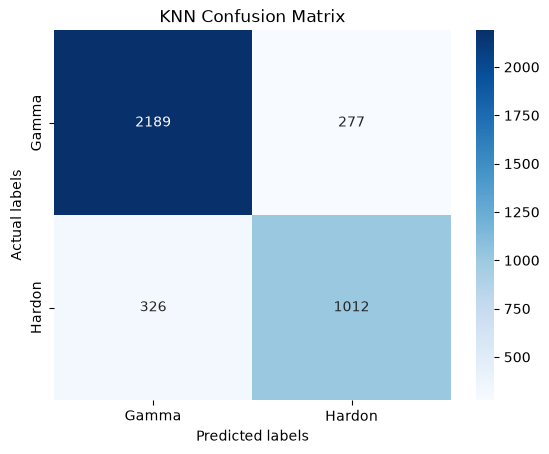

In [44]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Gamma","Hardon"],
    yticklabels=["Gamma","Hardon"],
    
)
plt.xlabel("Predicted labels")
plt.ylabel("Actual labels")
plt.title("KNN Confusion Matrix")
plt.show();

In [45]:
k_values=[3,5,7,9,11]
accuracy_values=[]
result={}
for k in [3,5,7,9,11]:
    pipeline=make_pipeline(
        StandardScaler(),
        RandomOverSampler(random_state=42),
        KNeighborsClassifier(n_neighbors=k)
    )
    scores=cross_val_score(
        pipeline,
        x_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )
    
    result[k]=scores
    accuracy_values.append(result[k].mean())
    

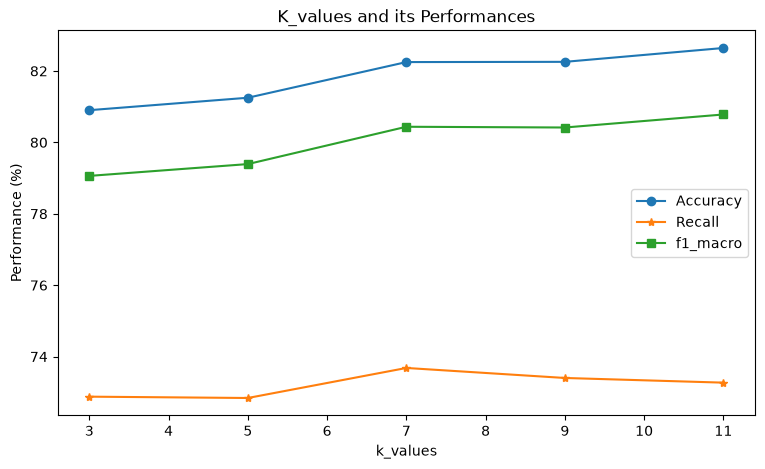

In [61]:
plt.figure(figsize=(9,5))
plt.plot(k_values,[score*100 for score in accuracy_values],marker="o",label="Accuracy")
plt.plot(k_values,[score*100 for score in hardon_recall_values],marker="*",label="Recall")
plt.plot(k_values,[score*100 for score in f1_macro_values],marker="s",label="f1_macro")
plt.xlabel("k_values")
plt.title("K_values and its Performances")
plt.ylabel("Performance (%)")
plt.legend()
plt.show();

In [57]:
print(np.array(accuracy_values)*100)

[80.9017335  81.25007827 82.24897796 82.25555043 82.64329758]


In [58]:
print(np.array(hardon_recall_values)*100)

[72.87850467 72.8411215  73.68224299 73.40186916 73.27102804]


In [59]:
print(np.array(f1_macro_values)*100)

[79.06148031 79.392189   80.4374939  80.41661588 80.78131438]
